# Make figures for the SCA comparison

Snow-Informed Reservoir Operations (SIRO)

USACE-ERDC-CRREL

July 2026

In [1]:
import os
from glob import glob
import xarray as xr
import rioxarray as rxr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
from tqdm import tqdm
import numpy as np
import seaborn as sns
import geopandas as gpd
import xrspatial
import string

plt.rcParams.update({'font.size': 12, 'font.sans-serif': 'Arial'})

# I/O
BASE_DIR = "/Users/rdcrlrka/Research/SIRO/SIRO_P1/MCS_SCA"
OUT_DIR = os.path.join(BASE_DIR, "SCA_comparison_results")
FIG_DIR = os.path.join(BASE_DIR, "figures")
AOI_FILE = "/Users/rdcrlrka/Research/SIRO/SIRO_P1/MCSModeling/MCS_outline/basin_outline.shp"
os.makedirs(FIG_DIR, exist_ok=True)

# Satellite-based fSCA
SPIRES_FSCA_FILE = os.path.join(OUT_DIR, "SPIReS_fSCA.nc")
LS_FSCA_FILE = os.path.join(OUT_DIR, "Landsat_fSCA.nc")
# Landsat images
LS_IMAGE_DICT = {
    date: sorted(glob(os.path.join(BASE_DIR, "Landsat_images", f"*{date}*SR_B*.TIF")))
    for date in ["20241205", "20250114"]
}

# Model names
MODEL_NAMES = ["HMS-EB", "HMS-TI", "iSnobal", "SnowModel"]
# Modify HMS display names
MODEL_NAMES_DISPLAY = {}
for m in MODEL_NAMES:
    if m=="HMS-EB":
        MODEL_NAMES_DISPLAY[m] = "HEC-HMS EB"
    elif m=="HMS-TI":
        MODEL_NAMES_DISPLAY[m] = "HEC-HMS TI"
    else:
        MODEL_NAMES_DISPLAY[m] = m

# Compiled result filess
METRICS_FILE = os.path.join(OUT_DIR, "compiled_performance_metrics.nc")
METRICS_BINNED_FILE = os.path.join(OUT_DIR, "compiled_metrics_binned_elev_aspect.nc")
MELT_OUT_BINNED_FILE = os.path.join(OUT_DIR, "compiled_melt_out_binned_elev_aspect.nc")
MELT_OUT_GRIDS_FILE = os.path.join(OUT_DIR, "melt_out_dates_gridded.nc")

# One gridded file per model
MODEL_GRID_FILES = {
    m: os.path.join(OUT_DIR, f"fSCA_regridded_{m}.nc") for m in MODEL_NAMES
}

for file in [SPIRES_FSCA_FILE, METRICS_FILE, METRICS_BINNED_FILE]:
    if not os.path.exists(file):
        print("Could not locate file:", file)
for m, f in MODEL_GRID_FILES.items():
    if not os.path.exists(f):
        print(f"Could not locate gridded file for {m}:", f)


LABEL_BOX = dict(facecolor='white', edgecolor='none', alpha=0.7, pad=1)
def add_panel_label(ax, label, loc='upper left', fontsize=14):
    # Determine xy and alignment based on location 
    # so there is always a 0.5 x 0.5 pad with the axes
    if loc=='upper left':
        x,y = 0.05, 0.95
        ha, va = 'left', 'top'
    elif loc=='upper right':
        x,y = 0.95, 0.95
        ha, va = 'right', 'top'
    elif loc=='lower left':
        x,y = 0.05, 0.05
        ha, va = 'left', 'bottom'
    elif loc=='lower right':
        x,y = 0.95, 0.05
        ha, va = 'right', 'bottom'

    ax.text(
        x, y, label, transform=ax.transAxes, ha=ha, va=va, 
        fontweight='bold', fontsize=fontsize, bbox=LABEL_BOX
        )


## Define some color palettes

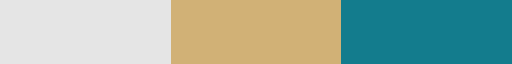

In [2]:
sca_cmap = matplotlib.colors.ListedColormap([
    "#e5e5e5",   # 0.0  -> no snow
    "#d1b176",   # 0.5  -> uncertain
    "#137C8D"   # 1.0  -> snow
])
sca_cmap.set_bad("#ffffff")  # NaN (unobserved)
# Boundaries centered so 0, 0.5, 1 fall in the middle of each color band
sca_cmap_norm = matplotlib.colors.BoundaryNorm([-0.25, 0.25, 0.75, 1.25], sca_cmap.N)
sca_cmap

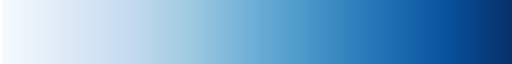

In [3]:
blues_colors = plt.colormaps['Blues'](np.linspace(0, 1, 256))
blues_colors[0] = [1.0, 1.0, 1.0, 1.0]
fsca_cmap = matplotlib.colors.ListedColormap(blues_colors)
fsca_cmap_norm = matplotlib.colors.Normalize(vmin=0, vmax=100)
fsca_cmap

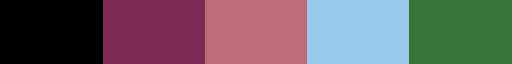

In [4]:
ds_colors_dict = {
    "SPIReS":  "#000000",
    "HMS-EB":       "#7D2B54",
    "HMS-TI":       "#BF6B78",
    "iSnobal":      "#97CAEA",
    "SnowModel":    "#37753B"
}
ds_colors = list(ds_colors_dict.values())
ds_cmap = matplotlib.colors.ListedColormap(ds_colors)
ds_cmap


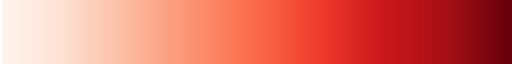

In [5]:
reds_colors = plt.colormaps['Reds'](np.linspace(0, 1, 256))
reds_colors[0] = [1.0, 1.0, 1.0, 1.0]
error_cmap = matplotlib.colors.ListedColormap(reds_colors)
error_cmap_norm = matplotlib.colors.Normalize(vmin=0, vmax=100)
error_cmap

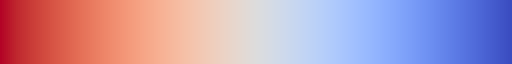

In [6]:
derr_cmap = plt.cm.coolwarm_r
derr_cmap_norm = matplotlib.colors.Normalize(vmin=-10, vmax=10)
derr_cmap

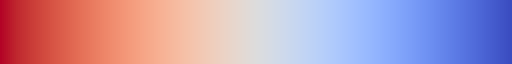

In [7]:
# melt out delay bias
bias_cmap = matplotlib.colormaps['coolwarm_r']
bias_norm = matplotlib.colors.TwoSlopeNorm(vmin=-30, vcenter=0, vmax=30)
bias_cmap

## fSCA time series

In [ ]:
# A few common variables and helper functions for map view plotting
import re

# AOI
AOI = gpd.read_file(AOI_FILE)

# fSCA datasets
spires_fsca = xr.open_dataset(SPIRES_FSCA_FILE, mask_and_scale=True).squeeze()
model_datasets = {m: xr.open_dataset(f, mask_and_scale=True).squeeze() for m, f in MODEL_GRID_FILES.items()}

# MODIS RGB (from process_modis_rgb.py)
MODIS_RGB_DIR = os.path.join(BASE_DIR, "MODIS_SR_daily")
MODIS_RGB_FILES = sorted(glob(os.path.join(MODIS_RGB_DIR, "MOD09A1_RGB_*_clip.tif")))
MODIS_RGB_DATES = pd.to_datetime(
    [re.search(r"(\d{8})", os.path.basename(f)).group(1) for f in MODIS_RGB_FILES], format="%Y%m%d"
    )

def normalize_band(band, vmin=0, vmax=0.4):
    """Clip and rescale reflectance to 0-1 for display."""
    clipped = np.clip(band, vmin, vmax)
    return (clipped - vmin) / (vmax - vmin)


def load_modis_rgb(dt):
    """
    Clipped MOD09A1 RGB for the composite at dt (an exact match, since dt comes from
    MODIS_RGB_DATES), as a display-ready (y, x, 3) array (pixels outside the AOI, already NaN
    from process_modis_rgb.py's clip, filled white), plus its (xmin, xmax, ymin, ymax) extent in km.
    """
    pos = MODIS_RGB_DATES.get_loc(dt)
    da = rxr.open_rasterio(MODIS_RGB_FILES[pos], masked=True).transpose('y', 'x', 'band')
    rgb = normalize_band(da.data)
    rgb = np.where(np.isnan(rgb), 1.0, rgb)
    extent = (float(da.x.min()) / 1e3, float(da.x.max()) / 1e3, float(da.y.min()) / 1e3, float(da.y.max()) / 1e3)
    return rgb, extent

def nearest_fsca(da, dt, tolerance=pd.Timedelta("1D")):
    """
    DataArray at the date in da nearest to dt, or None if nothing falls within tolerance.
    """
    try:
        return da.sel(time=dt, method="nearest", tolerance=tolerance)
    except KeyError:
        return None



### Time series GIF

In [ ]:

gif_dir = os.path.join(FIG_DIR, "fSCA_timeseries_gif")
os.makedirs(gif_dir, exist_ok=True)

ms=5
lw = 0.5

# --- Precompute basin-mean fSCA time series once (task & SWE-threshold averaged), reused for every frame ---
spires_mean_series = spires_fsca.snow_fraction.mean(dim=['x', 'y'])  # already in %
model_mean_series = {
    m: ds.fSCA.mean(dim=['x', 'y']).mean(dim=['task', 'SWE_threshold_m']) * 100
    for m, ds in model_datasets.items()
}
ts_xlim = (spires_fsca.time.min().data, spires_fsca.time.max().data)


# --- Plot frames ---
for dt in tqdm(MODIS_RGB_DATES):
    fig_file = os.path.join(gif_dir, f"fSCA_{pd.Timestamp(dt).strftime("%Y%m%d")}.png")
    if os.path.exists(fig_file):
        continue

    # Select data (nearest SPIReS/model date within tolerance)
    spires_fsca_date = nearest_fsca(spires_fsca.snow_fraction, dt)
    model_datasets_date = {
        m: nearest_fsca(ds.fSCA, dt) for m, ds in model_datasets.items()
    }

    # Plot
    gs = matplotlib.gridspec.GridSpec(3, 3, height_ratios=[2,2,1])
    fig = plt.figure(figsize=(10,10))
    ax = [
        fig.add_subplot(gs[0,0]), fig.add_subplot(gs[0,1]), fig.add_subplot(gs[0,2]),
        fig.add_subplot(gs[1,0]), fig.add_subplot(gs[1,1]), fig.add_subplot(gs[1,2]),
        fig.add_subplot(gs[2,:])
    ]
    # RGB image
    rgb, rgb_extent = load_modis_rgb(dt)
    if rgb is not None:
        ax[0].imshow(rgb, extent=rgb_extent)
    ax[0].set_title("MODIS RGB")
    # fSCA
    # SPIReS
    if spires_fsca_date is not None:
        im = ax[3].imshow(
            spires_fsca_date.data, cmap=fsca_cmap, norm=fsca_cmap_norm,
            extent=(min(spires_fsca_date.x)/1e3, max(spires_fsca_date.x)/1e3, min(spires_fsca_date.y)/1e3, max(spires_fsca_date.y)/1e3)
            )
    ax[3].set_title("SPIReS")
    # Models
    for model, iaxis in list(zip(
        model_datasets.keys(), [1, 2, 4, 5]
    )):
        fsca_model = model_datasets_date[model]
        if fsca_model is not None:
            ax[iaxis].imshow(
                (fsca_model.mean(dim=['task', 'SWE_threshold_m']) * 100), cmap=fsca_cmap, norm=fsca_cmap_norm,
                extent=(min(fsca_model.x)/1e3, max(fsca_model.x)/1e3, min(fsca_model.y)/1e3, max(fsca_model.y)/1e3)
            )
        ax[iaxis].set_title(MODEL_NAMES_DISPLAY[model])

    # AOI
    for axis in ax[0:-1]:
        axis.plot(
        np.divide(AOI.geometry[0].exterior.coords.xy[0], 1e3), np.divide(AOI.geometry[0].exterior.coords.xy[1], 1e3), 
        '-k', linewidth=1
        )
        axis.set_xticks([])
        axis.set_yticks([])

    # colorbar
    cax = fig.add_axes([0.97, 0.5, 0.03, 0.3])
    fig.colorbar(matplotlib.cm.ScalarMappable(cmap=fsca_cmap, norm=fsca_cmap_norm), cax=cax, label="fSCA (%)")

    # --- fSCA time series, truncated to this date ---
    past = spires_mean_series.time <= dt
    
    for model, series in model_mean_series.items():
        past = series.time <= dt
        ax[6].plot(
            series.time[past], series.data[past], '.-', linewidth=lw, markersize=ms,
            color=ds_colors_dict[model], label=MODEL_NAMES_DISPLAY[model]
            )
    ax[6].plot(
        spires_mean_series.time[past], spires_mean_series.data[past], '.-', linewidth=lw, markersize=ms,
        color=ds_colors_dict['SPIReS'], label='SPIReS'
        )
    ax[6].set_xlim(*ts_xlim)
    ax[6].set_ylim(0, 105)
    ax[6].set_ylabel("fSCA [%]")
    ax[6].set_xlabel("Date")
    ax[6].legend(loc='upper center', ncols=5, frameon=False, bbox_to_anchor=(0.5, 1.3))

    fig.suptitle(pd.Timestamp(dt).strftime("%Y-%m-%d"))
    # fig.tight_layout()

    fig.savefig(fig_file, dpi=200, bbox_inches='tight')
    plt.close()

In [ ]:
# --- Make GIF ---
gif_file = os.path.join(FIG_DIR, "fSCA_timeseries.gif")
if not os.path.exists(gif_file):
    from PIL import Image

    def make_gif(image_files, out_file, duration=500, loop=1):
        frames = [Image.open(f).convert("RGB") for f in image_files]
        frames[0].save(
            out_file, format="GIF", save_all=True, append_images=frames[1:],
            duration=duration, loop=loop
            )
        print(f"GIF saved to: {out_file}")


    frame_files = sorted(glob(os.path.join(gif_dir, "fSCA*.png")))
    make_gif(frame_files, gif_file, duration=500)

else:
    print("GIF already exists, skipping:", gif_file)

### Example map frames

KeyError: '2023-12-19'

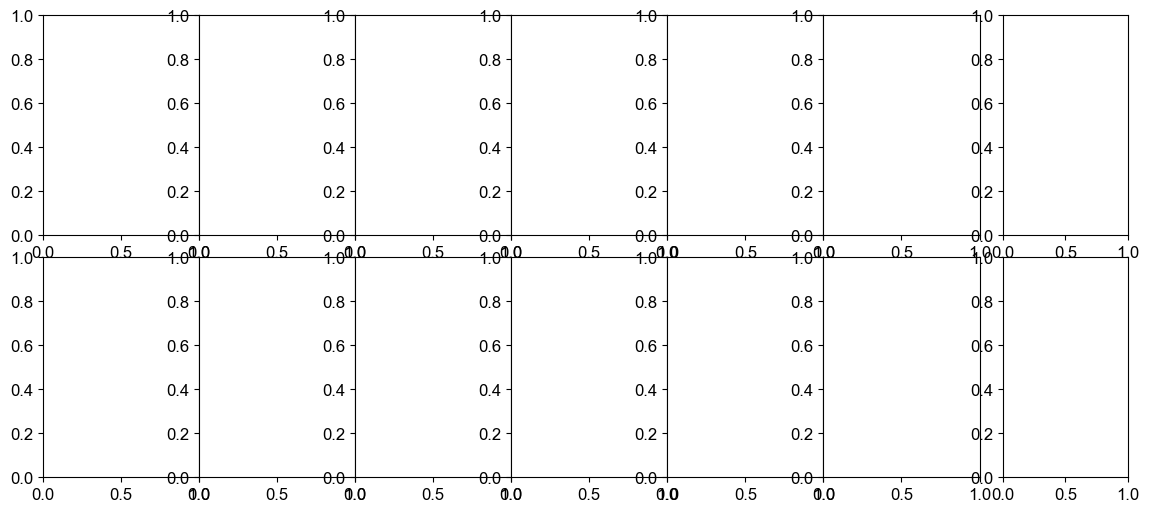

In [9]:
ms = 5
lw = 1

dates = [
    "2023-12-19",   # Accum. season
    "2025-05-25"    # Late melt season
]

gs = matplotlib.gridspec.GridSpec(2, 8, width_ratios=[1,1,1,1,1,1,0.15,0.8], wspace=0, hspace=0.1)
fig = plt.figure(figsize=(14,6))
ax = np.empty((2, 7), dtype=object)
for i in range(2):
    for j in range(6):
        ax[i, j] = fig.add_subplot(gs[i, j])
    ax[i, 6] = fig.add_subplot(gs[i, 7])  # skip the spacer at index 6

# Match the map panels' rendered box aspect in the error-bar panel
xmin, ymin, xmax, ymax = AOI.total_bounds
aoi_box_aspect = (ymax - ymin) / (xmax - xmin) / 0.8

# --- Plot frame ---
for i, date in enumerate(dates):

    dt = pd.Timestamp(date)

    # Load data
    spires_fsca_date = nearest_fsca(spires_fsca.snow_fraction, dt)
    model_datasets_date = {
        m: nearest_fsca(ds.fSCA, dt) for m, ds in model_datasets.items()
    }
    rgb, rgb_extent = load_modis_rgb(date)

    # MODIS RGB image
    ax[i,0].imshow(np.multiply(rgb, 1.3), extent=rgb_extent)
        
    # SPIReS fSCA
    im = ax[i,1].imshow(
        spires_fsca_date.data, cmap=fsca_cmap, norm=fsca_cmap_norm,
        extent=(min(spires_fsca_date.x)/1e3, max(spires_fsca_date.x)/1e3, min(spires_fsca_date.y)/1e3, max(spires_fsca_date.y)/1e3)
        )
    if i==0:
        ax[i,0].set_title("MODIS RGB")
        ax[i,1].set_title("SPIReS")

    # Modeled fSCA
    for j, model in enumerate(list(model_datasets.keys())):
        fsca_model = model_datasets_date[model]

        # Map view
        ax[i,j+2].imshow(
            (fsca_model.mean(dim=['task', 'SWE_threshold_m']) * 100), cmap=fsca_cmap, norm=fsca_cmap_norm,
            extent=(min(fsca_model.x)/1e3, max(fsca_model.x)/1e3, min(fsca_model.y)/1e3, max(fsca_model.y)/1e3)
        )
        if i==0:
            ax[i,j+2].set_title(MODEL_NAMES_DISPLAY[model], color=ds_colors_dict[model], fontweight='bold')

        # Basin-mean fSCA for each task/SWE-threshold run, then summarize across runs
        run_means = fsca_model.mean(dim=['x', 'y']) * 100   # dims: task, SWE_threshold_m
        run_mean = float(run_means.mean(dim=['task', 'SWE_threshold_m']))
        run_min = float(run_means.min(dim=['task', 'SWE_threshold_m']))
        run_max = float(run_means.max(dim=['task', 'SWE_threshold_m']))

        # Error bar: point at the mean, whiskers to the min/max across runs
        ax[i,-1].errorbar(
            [j], [run_mean],
            yerr=[[run_mean - run_min], [run_max - run_mean]],
            fmt='o', ms=ms, elinewidth=lw, capsize=3, color=ds_colors_dict[model]
            )

    ax[i,0].set_ylabel(date, fontweight='bold')

    # Format the error-bar panel
    ax[i,-1].set_box_aspect(aoi_box_aspect)
    ax[i,-1].axhline(spires_fsca_date.mean(dim=['x', 'y']).values, lw=lw*2, color='k')
    ax[i,-1].set_xlim(-0.5, len(model_datasets) - 0.5)
    ax[i,-1].set_ylim(0, 105)
    ax[i,-1].set_xticks(range(len(model_datasets)))
    ax[i,-1].yaxis.tick_right()
    ax[i,-1].yaxis.set_label_position("right")
    ax[i,-1].set_ylabel("fSCA (%)")
    ax[i,-1].grid(lw=lw/3)
    if i == 0:
        ax[i,-1].set_title("Watershed-wide\nfSCA")
    if i>0:
        ax[i,-1].set_xticklabels(
            [MODEL_NAMES_DISPLAY[m] for m in model_datasets.keys()], rotation=90
            )
    else:
        ax[i,-1].set_xticklabels(['']*len(model_datasets))

    
# Map views
for axis in ax[:,0:-1].flatten():
    # Plot AOI
    axis.plot(
    np.divide(AOI.geometry[0].exterior.coords.xy[0], 1e3), np.divide(AOI.geometry[0].exterior.coords.xy[1], 1e3), 
    '-k', linewidth=1
    )
    axis.set_xticks([])
    axis.set_yticks([])


# Panel labels
for i, axis in enumerate(ax.flatten()):
    add_panel_label(axis, string.ascii_lowercase[i], loc='lower right')

ax[1,-1].set_ylim(-1,15)

# Colorbar
cbar_xmid =  (
    ax[1,1].get_position().x0 
    + ax[1,-2].get_position().x0 + ax[1,-2].get_position().width
    ) / 2
cbar_width = 0.3
cax = fig.add_axes([cbar_xmid-cbar_width/2, 0.05, cbar_width, 0.03])
fig.colorbar(
    matplotlib.cm.ScalarMappable(cmap=fsca_cmap, norm=fsca_cmap_norm), 
    cax=cax, label="fSCA (%)", orientation='horizontal'
    )


plt.show()

fig_file = os.path.join(FIG_DIR, "fSCA_map_view_examples.png")
fig.savefig(fig_file, dpi=300, bbox_inches='tight')
print("Figure saved to:", fig_file)

### Comparison: Both tasks, then task 1 only

In [ ]:
for task in ['both', '1', '2']:

    # Create figure
    fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [2.5, 1]})
    fig.subplots_adjust(wspace=0.15)
    grid_alpha = 0.5
    grid_lw = 1

    # create NaN array to concat with each dataset to prevent lines from connecting where there are no data
    nan_da = xr.DataArray(
        np.array([np.nan]*4), 
        coords={'time': [np.datetime64(f"{year}-08-01") for year in [2022, 2023, 2024, 2025]]}
    )

    # Load SPIReS and Landsat fSCA
    with xr.open_dataset(SPIRES_FSCA_FILE, mask_and_scale=True) as spires_fsca:
        spires_fsca_mean = spires_fsca.snow_fraction.mean(dim=['x', 'y'])
        spires_fsca_mean_plot = xr.concat([spires_fsca_mean, nan_da], dim='time').sortby('time')

    with xr.open_dataset(LS_FSCA_FILE, mask_and_scale=True) as ls_fsca:
        ls_fsca_mean = ls_fsca.band_data.mean(dim=['x', 'y'])


    # Prepare a list to collect difference dataframes for the boxplot
    diff_df_list = []

    # Models
    for m in MODEL_GRID_FILES.keys():
        with xr.open_dataset(MODEL_GRID_FILES[m], mask_and_scale=True) as m_fsca:
            m_fsca_mean = m_fsca.mean(dim=['x', 'y']).fSCA * 100

            # Do the task selection
            if task=='1':
                m_fsca_mean = m_fsca_mean.isel(task=0)
                stat_dims = ['SWE_threshold_m']
            elif task=='2':
                m_fsca_mean = m_fsca_mean.isel(task=1)
                stat_dims = ['SWE_threshold_m']
            else:
                stat_dims = ['task', 'SWE_threshold_m']

            # Calculate min, max, and mean across all tasks and SWE thresholds
            m_min = m_fsca_mean.min(dim=stat_dims)
            m_max = m_fsca_mean.max(dim=stat_dims)
            m_mean = m_fsca_mean.mean(dim=stat_dims)
            
            # Add NaNs for plotting breaks
            m_min_plot = xr.concat([m_min, nan_da], dim='time').sortby('time')
            m_max_plot = xr.concat([m_max, nan_da], dim='time').sortby('time')
            m_mean_plot = xr.concat([m_mean, nan_da], dim='time').sortby('time')

            # Fill between encompasses all tasks and SWE thresholds now
            ax[0].fill_between(
                m_mean_plot.time, m_min_plot, m_max_plot, 
                color=ds_colors_dict[m], alpha=0.3
            )    
            ax[0].plot(
                m_mean_plot.time, m_mean_plot, 
                color=ds_colors_dict[m], label=MODEL_NAMES_DISPLAY[m]
            )
            
            # --- Box plot data prep ---
            # Align times between model and SPIReS to calculate valid differences (dropping added NaNs)
            m_clean = m_mean.dropna(dim='time')
            spires_clean = spires_fsca_mean.dropna(dim='time')
            
            m_aligned, spires_aligned = xr.align(m_clean, spires_clean, join='inner')
            diff = m_aligned - spires_aligned
            
            # Convert to DataFrame for Seaborn
            df = diff.to_dataframe(name='Difference').reset_index()
            df['Model'] = m
            df['Month'] = df['time'].dt.month
            diff_df_list.append(df)

    # Plot SPIReS fSCA
    ax[0].plot(spires_fsca_mean_plot.time, spires_fsca_mean_plot.data, 
            color=ds_colors_dict["SPIReS"], label="SPIReS")

    # Plot dates being shown in previous figure
    for date in dates:
        ax[0].axvline(
            np.datetime64(date), 
            color='k', linestyle='--', alpha=0.8
            )

    # --- Format time series panel ---
    ax[0].set_ylabel("fSCA [%]")
    ax[0].set_xlim(np.datetime64("2022-09-01"), np.datetime64("2025-07-01"))
    ax[0].set_ylim(0,105)

    # Label years as major x-axis, months as minor x-axis
    ax[0].tick_params(axis='x', which='major', rotation=0, labelsize=12)
    ax[0].grid(which='major', alpha=grid_alpha, linewidth=grid_lw)
    ax[0].set_xlabel("Date")

    # --- Format boxplot panel ---
    all_diffs = pd.concat(diff_df_list, ignore_index=True)

    # Define water year order
    water_year_months = [10, 11, 12, 1, 2, 3, 4, 5, 6]
    water_year_labels = ['Oct', '', 'Dec', '', 'Feb', '', 'Apr', '', 'Jun']

    # Filter dataframe to only include the target water year months
    water_year_diffs = all_diffs[all_diffs['Month'].isin(water_year_months)]

    # Plot difference boxplots ordered the water year
    sns.boxplot(
        data=water_year_diffs, x='Month', y='Difference', hue='Model', 
        order=water_year_months, palette=ds_colors_dict, ax=ax[1], 
        showfliers=False, linecolor='auto'
    )
    # Make whisker colors match box colors
    for patch, line in zip(ax[1].artists, ax[1].lines):
        color = patch.get_facecolor()
        patch.set_edgecolor(color)
        line.set_color(color)

    # Map the numeric x-ticks to string month abbreviations
    ax[1].set_xticklabels(water_year_labels)

    # Adjustments
    ax[1].set_ylabel("Modeled - SPIReS fSCA [%]")
    ax[1].grid(axis='y', which='major', alpha=grid_alpha, linewidth=grid_lw)
    ax[1].set_xticks(np.arange(0.5, 8.5, 1.0), minor=True)
    ax[1].tick_params(axis='x', which='minor', length=0)
    ax[1].grid(axis='x', which='minor', alpha=grid_alpha, linewidth=grid_lw)
    
    ax[1].axhline(0, color='k', alpha=grid_alpha, linestyle='-', linewidth=grid_lw)

    # Legend
    ax[1].legend_.remove() 
    handles, labels = ax[0].get_legend_handles_labels()
    leg = fig.legend(
        handles, labels, loc='upper center', ncols=6, frameon=False,
        handletextpad=0.3, bbox_to_anchor=(0.5, 1.02)
    )

    # Panel labels
    fs = 16
    ax[0].text(
        0.02, 0.95, 'a', transform=ax[0].transAxes, fontsize=fs,
        ha='left', va='top', fontweight='bold', bbox=LABEL_BOX
        )
    add_panel_label(ax[1], 'b', loc='upper left', fontsize=fs)

    plt.show()

    fig_file = os.path.join(FIG_DIR, "fSCA_timeseries_and_diffs.png")
    if task!='both':
        fig_file = fig_file.replace(".png", f"_TASK{task}.png")
    fig.savefig(fig_file, dpi=300, bbox_inches='tight')
    print("fSCA figure saved to:", fig_file)


## Melt out day delays

In [ ]:
def plot_recall_polar(terrain_bin_da, elev_bin_edges, aspect_bin_edges, cmap, cmap_norm, ax=None):
    # Create the axis if needed
    if ax==None:
        fig = plt.figure(figsize=(6, 6))
        ax = fig.add_subplot(111, projection='polar')

    ax.set_theta_zero_location('N')     # top = N
    ax.set_theta_direction(-1)          # Clockwise

    # Get bin centers and widths for elevation and aspect
    elev_bin_width = elev_bin_edges[1] - elev_bin_edges[0]
    elev_centers = (elev_bin_edges[1:] + elev_bin_edges[:-1]) / 2
    aspect_bin_width = aspect_bin_edges[1] - aspect_bin_edges[0]
    aspect_centers = (aspect_bin_edges[:-1] + aspect_bin_edges[1:]) / 2
    theta_centers = np.deg2rad(aspect_centers)

    # Iterate over elevation and aspect bin centers
    for i, elev in enumerate(elev_centers):
        for j, theta in enumerate(theta_centers):
            val = terrain_bin_da.data[i, j]
            color = 'whitesmoke' if np.isnan(val) else cmap(cmap_norm(val))
            ax.bar(
                x=theta,
                height=elev_bin_width,
                bottom=elev_bin_edges[i],
                width=np.deg2rad(aspect_bin_width),
                color=color,
                edgecolor='none',
                align='center'
            )

    ax.set_xticks(np.deg2rad(np.arange(0,360,45)))
    ax.set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
    ax.set_ylim(500, 2500)
    ax.set_yticks(np.arange(1000, 3000, 500))
    ax.set_yticklabels([f"{x:.0f} m" for x in ax.get_yticks()], fontsize=9)
    ax.grid(color='k', alpha=0.3)

    return

In [ ]:
melt_out_binned = xr.open_dataset(MELT_OUT_BINNED_FILE, mask_and_scale=True).squeeze()
melt_out_grids = xr.open_dataset(MELT_OUT_GRIDS_FILE, mask_and_scale=True)

elev_bin_edges = np.array(melt_out_binned.attrs['elev_bins'])
aspect_bin_edges = np.array(melt_out_binned.attrs['aspect_bins'])
water_years = melt_out_grids.water_year.data
model_names = melt_out_binned.model.data
n_models = len(model_names)

fig = plt.figure(figsize=(3 * n_models, 6))
gs = fig.add_gridspec(2, n_models, height_ratios=[1.5, 1])

polar_axes, time_axes = [], []
for j, model in enumerate(model_names):
    da = melt_out_binned.sel(model=model)

    # --- Terrain polar panel: mean bias across water years, tasks, SWE thresholds ---
    ax_polar = fig.add_subplot(gs[0, j], projection='polar')
    da_mean = (
        da['melt_out_bias_days']
        .mean(dim='water_year', skipna=True)
        .max(dim='SWE_threshold_m', skipna=True)
        .mean(dim='task', skipna=True)
    )
    plot_recall_polar(
        da_mean, cmap=bias_cmap, cmap_norm=bias_norm, ax=ax_polar,
        elev_bin_edges=elev_bin_edges, aspect_bin_edges=aspect_bin_edges,
    )
    ax_polar.set_title(MODEL_NAMES_DISPLAY[model])
    if j == 0:
        ax_polar.set_ylabel("Melt-out bias\nwith terrain\n\n")
    polar_axes.append(ax_polar)

    # --- Interannual spread of pixel-level melt-out differences ---
    ax_time = fig.add_subplot(gs[1, j])
    model_grid = melt_out_grids['model_melt_out_dowy'].sel(model=model)

    diffs_by_year = []
    for wy in water_years:
        model_dowy = (
            model_grid.sel(water_year=wy)
            .max(dim='SWE_threshold_m', skipna=True)
            .mean(dim='task', skipna=True)
        )
        ref_dowy = melt_out_grids['SPIReS_melt_out_dowy'].sel(water_year=wy)
        diff = (model_dowy - ref_dowy).values.ravel()
        diffs_by_year.append(diff[~np.isnan(diff)])

    bp = ax_time.boxplot(
        diffs_by_year, positions=water_years, widths=0.6,
        showfliers=False, patch_artist=True,
        boxprops=dict(facecolor='#bdbdbd'),
        medianprops=dict(color="k", linewidth=1),
    )

    ax_time.axhline(0, color='k', lw=1, ls='-')
    ax_time.set_xlabel("Water year")
    ax_time.tick_params(axis='x')#, rotation=45)
    ax_time.set_xlim(2022.5, 2025.5)
    ax_time.set_ylim(-45, 80)
    if j == 0:
        ax_time.set_ylabel("Melt-out day difference\n(model $-$ SPIReS)")
    time_axes.append(ax_time)

# Colorbar for the terrain row
ref_ax = polar_axes[-1]
pos = ref_ax.get_position()
c_ax = fig.add_axes([pos.x0 + pos.width + 0.03, pos.y0, 0.01, pos.height])
cbar = fig.colorbar(
    matplotlib.cm.ScalarMappable(cmap=bias_cmap, norm=bias_norm), cax=c_ax, 
    orientation='vertical', spacing='proportional'
)
cbar.ax.set_yscale('linear')
cbar.ax.set_title("Melt-out\nbias [days]\n")

# adjust aspect labels that are overlapping
polar_axes[0].set_xticklabels(['N', 'NE', '', 'SE', 'S', 'SW', 'W', 'NW'])
polar_axes[1].set_xticklabels(['N', 'NE', '', 'SE', 'S', 'SW', '', 'NW'])
polar_axes[2].set_xticklabels(['N', 'NE', '', 'SE', 'S', 'SW', '', 'NW'])
polar_axes[3].set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', '', 'NW'])

# panel labels
fs = 14
for i, axis in enumerate(polar_axes):
    axis.text(
        0.0, 1.1, string.ascii_lowercase[i], transform=axis.transAxes, 
        fontweight='bold', bbox=LABEL_BOX, ha='left', va='top', fontsize=fs,
        )
for i, axis in enumerate(time_axes):
    add_panel_label(axis, string.ascii_lowercase[i+4], loc='upper left', fontsize=fs)


plt.show()

fig_file = os.path.join(FIG_DIR, "melt_out_differences_terrain_time.png")
fig.savefig(fig_file, dpi=300, bbox_inches='tight')
print("Figure saved to:", fig_file)

In [ ]:
dbias_cmap = matplotlib.colormaps['PuOr']
dbias_norm = matplotlib.colors.TwoSlopeNorm(vmin=-30, vcenter=0, vmax=30)

fig2 = plt.figure(figsize=(4 * n_models, 6))
gs2 = fig.add_gridspec(2, n_models, height_ratios=[1.5, 1])

task_colors = {1: '#1b9e77', 2: '#d95f02'} 
box_width = 0.35
offset = 0.22

polar_axes2, time_axes2 = [], []
for j, model in enumerate(model_names):
    da = melt_out_binned.sel(model=model)

    # --- Terrain polar panel: unchanged, still Task 2 - Task 1 ---
    ax_polar = fig2.add_subplot(gs2[0, j], projection='polar')
    da_diff = (
        da['melt_out_bias_days']
        .mean(dim='water_year', skipna=True)
        .max(dim='SWE_threshold_m', skipna=True)
        .diff(dim='task')
        .squeeze()
    )
    plot_recall_polar(
        da_diff, cmap=dbias_cmap, cmap_norm=dbias_norm, ax=ax_polar,
        elev_bin_edges=elev_bin_edges, aspect_bin_edges=aspect_bin_edges,
    )
    ax_polar.set_title(MODEL_NAMES_DISPLAY[model])
    if j == 0:
        ax_polar.set_ylabel("Melt-out bias\nAssimilation $-$ Baseline Run\n\n")
    polar_axes2.append(ax_polar)

    # --- Interannual spread: each task's own distribution, side by side ---
    ax_time = fig2.add_subplot(gs2[1, j])
    model_grid = melt_out_grids['model_melt_out_dowy'].sel(model=model)

    for task, sign in zip(model_grid.task.values, (-1, 1)):
        task_dowy_by_year = model_grid.sel(task=task).max(dim='SWE_threshold_m', skipna=True)
        diffs_by_year = []
        for wy in water_years:
            vals = task_dowy_by_year.sel(water_year=wy).values.ravel()
            diffs_by_year.append(vals[~np.isnan(vals)])

        bp = ax_time.boxplot(
            diffs_by_year, positions=water_years + sign * offset, widths=box_width,
            showfliers=False, patch_artist=True,
            boxprops=dict(facecolor=task_colors[task]),
            medianprops=dict(color="k", linewidth=1),
        )

    ax_time.set_xticks(water_years)
    ax_time.set_xticklabels(water_years)
    ax_time.set_xlabel("Water year")
    ax_time.tick_params(axis='x')#, rotation=45)
    ax_time.set_xlim(2022.5, 2025.5)
    if j == 0:
        ax_time.set_ylabel("Melt-out day\n(DOWY)")
    time_axes2.append(ax_time)

# Legend for task colors (once, e.g. on the last time panel)
labels = ["Baseline Run", "Assimilation Run"]
legend_handles = [
    matplotlib.patches.Patch(facecolor=color, label=labels[i])
    for i, (task, color) in enumerate(task_colors.items())
]
time_axes2[-1].legend(
    handles=legend_handles, loc='center right', frameon=False,
    bbox_to_anchor=[1.55, 0.4, 0.2, 0.2]
    )

# Colorbar for the terrain row
ref_ax = polar_axes2[-1]
pos = ref_ax.get_position()
c_ax = fig2.add_axes([pos.x0 + pos.width + 0.03, pos.y0, 0.01, pos.height])
cbar = fig2.colorbar(
    matplotlib.cm.ScalarMappable(cmap=dbias_cmap, norm=dbias_norm), cax=c_ax,
    orientation='vertical', spacing='proportional'
)
cbar.ax.set_title("$\\Delta$Melt-out\nbias [days]\n")


# panel labels
fs = 14
for i, axis in enumerate(polar_axes2):
    axis.text(
        0.0, 1.1, string.ascii_lowercase[i], transform=axis.transAxes, 
        fontweight='bold', bbox=LABEL_BOX, ha='left', va='top', fontsize=fs
        )
for i, axis in enumerate(time_axes2):
    add_panel_label(axis, string.ascii_lowercase[i+4], loc='upper left', fontsize=fs)
    # ylims
    axis.set_ylim(130,280)

plt.show()

fig2_file = os.path.join(FIG_DIR, "melt_out_differences_between_tasks.png")
fig2.savefig(fig2_file, dpi=300, bbox_inches='tight')
print("Figure saved to:", fig2_file)


## Summary statistics for the results text

In [ ]:
# ----- Summary statistics for the fSCA and melt-out results text -----
from IPython.display import display

TASK_LABELS = {1: "Baseline Run", 2: "Assimilation Run"}
WY_MONTHS = [10, 11, 12, 1, 2, 3, 4, 5, 6]
MONTH_LABELS = {10: "Oct", 11: "Nov", 12: "Dec", 1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun"}
FULL_COVER = 99.5  # basin-mean fSCA [%] counted as 100% snow cover

def summarize(values):
    """Median, IQR, and percent positive of a 1-D array of differences (NaNs dropped)."""
    values = pd.Series(np.asarray(values).ravel()).dropna()
    return pd.Series({
        "median": values.median(), 
        "Q1": values.quantile(0.25), 
        "Q3": values.quantile(0.75),
        "% > 0": 100 * (values > 0).mean(), 
        "n": len(values),
    })

# --- fSCA ---
with xr.open_dataset(SPIRES_FSCA_FILE, mask_and_scale=True) as ds:
    spires_mean = ds.snow_fraction.mean(dim=["x", "y"]).load()

fsca_dfs = []
for m, f in MODEL_GRID_FILES.items():
    with xr.open_dataset(f, mask_and_scale=True) as ds:
        model_mean = (ds.fSCA.mean(dim=["x", "y"]) * 100).load()  # (task, SWE_threshold_m, time)
    model_mean, ref_mean = xr.align(model_mean, spires_mean.dropna("time"), join="inner")
    df = xr.Dataset({"model_fSCA": model_mean, "dfSCA": model_mean - ref_mean}).to_dataframe().reset_index()
    df["model"] = m
    fsca_dfs.append(df)
fsca = pd.concat(fsca_dfs, ignore_index=True)
fsca["month"] = fsca["time"].dt.month
fsca = fsca[fsca["month"].isin(WY_MONTHS)]
fsca["run"] = fsca["task"].map(TASK_LABELS)

# Average over runs and SWE thresholds, then summarize over days
fsca_fig = fsca.groupby(["model", "time", "month"], as_index=False)["dfSCA"].mean()

print("fSCA difference by month [%], figure values: median over days")
display(fsca_fig.groupby(["model", "month"])["dfSCA"].median().unstack("month")[WY_MONTHS]
        .rename(columns=MONTH_LABELS).round(1))

print("fSCA difference, Nov-Dec, figure values")
display(fsca_fig[fsca_fig["month"].isin([11, 12])].groupby("model")["dfSCA"].apply(summarize).unstack().round(1))

print("fSCA difference, Oct-Jun, by run and SWE threshold: median [%]")
display(fsca.groupby(["model", "run", "SWE_threshold_m"])["dfSCA"].median().unstack("SWE_threshold_m").round(1))

print("fSCA difference, Oct-Jun, by run and SWE threshold: % of days with model > SPIReS")
display(fsca.groupby(["model", "run", "SWE_threshold_m"])["dfSCA"].apply(lambda s: 100 * (s > 0).mean())
        .unstack("SWE_threshold_m").round(0))

# Assimilation effect: paired (Assimilation - Baseline) difference in modeled fSCA, same day and threshold
paired = fsca.pivot_table(index=["model", "SWE_threshold_m", "time", "month"], columns="run", values="model_fSCA")
paired["change"] = paired["Assimilation Run"] - paired["Baseline Run"]
paired = paired.reset_index()
print("Change in modeled fSCA with assimilation (Assimilation - Baseline) [%]")
display(pd.concat({
    "Oct-Jun": paired.groupby("model")["change"].apply(summarize).unstack()[["median", "Q1", "Q3"]],
    "Nov-Dec": paired[paired["month"].isin([11, 12])].groupby("model")["change"].apply(summarize).unstack()[["median", "Q1", "Q3"]],
}, axis=1).round(1))

print(f"Days with basin-mean fSCA >= {FULL_COVER}% (Oct-Jun); SPIReS:",
      int((spires_mean.to_series()[lambda s: s.index.month.isin(WY_MONTHS)] >= FULL_COVER).sum()),
      f"days (max basin-mean SPIReS fSCA = {float(spires_mean.max()):.1f}%)")
display(fsca.groupby(["model", "run", "SWE_threshold_m"])["model_fSCA"].apply(lambda s: int((s >= FULL_COVER).sum()))
        .unstack("SWE_threshold_m"))

# --- Melt-out day ---
with xr.open_dataset(MELT_OUT_GRIDS_FILE, mask_and_scale=True) as ds:
    model_dowy = ds["model_melt_out_dowy"].load()
    ref_dowy = ds["SPIReS_melt_out_dowy"].load()
valid_wys = [int(wy) for wy in ref_dowy.water_year.values
             if np.isfinite(ref_dowy.sel(water_year=wy)).any() and np.isfinite(model_dowy.sel(water_year=wy)).any()]
model_dowy, ref_dowy = model_dowy.sel(water_year=valid_wys), ref_dowy.sel(water_year=valid_wys)
print(f"\nMelt-out comparisons use water years {valid_wys}")

melt_diff = model_dowy - ref_dowy 
melt_diff_fig = model_dowy.max(dim="SWE_threshold_m").mean(dim="task") - ref_dowy
melt_diff_run = model_dowy.max(dim="SWE_threshold_m") - ref_dowy

print("Melt-out difference [days], figure values, all pixels and water years")
display(pd.DataFrame({m: summarize(melt_diff_fig.sel(model=m).values) for m in melt_diff_fig.model.values}).T.round(1))

print("Median melt-out difference [days] by water year, figure values")
display(pd.DataFrame({m: {wy: np.nanmedian(melt_diff_fig.sel(model=m, water_year=wy).values) for wy in valid_wys}
                      for m in melt_diff_fig.model.values}).T.round(1))

print("Melt-out difference [days] by run (max over SWE thresholds)")
display(pd.DataFrame({(m, TASK_LABELS[int(t)]): summarize(melt_diff_run.sel(model=m, task=t).values)
                      for m in melt_diff_run.model.values for t in melt_diff_run.task.values}).T.round(1))

print("Change in melt-out day with assimilation (Assimilation - Baseline) [days], per pixel, max over SWE thresholds")
run_change = model_dowy.max(dim="SWE_threshold_m").sel(task=2) - model_dowy.max(dim="SWE_threshold_m").sel(task=1)
display(pd.DataFrame({m: summarize(run_change.sel(model=m).values) for m in run_change.model.values}).T.round(1))

print("Median melt-out difference [days] by SWE threshold (both runs pooled)")
display(pd.DataFrame({m: {thr: np.nanmedian(melt_diff.sel(model=m, SWE_threshold_m=thr).values)
                          for thr in melt_diff.SWE_threshold_m.values}
                      for m in melt_diff.model.values}).T.round(1))

# --- Melt-out difference with terrain ---
with xr.open_dataset(MELT_OUT_BINNED_FILE, mask_and_scale=True) as ds:
    binned = ds.sel(water_year=valid_wys).load()
    elev_edges, aspect_edges = np.array(ds.attrs["elev_bins"]), np.array(ds.attrs["aspect_bins"])
bias_bins = binned["melt_out_bias_days"].mean(dim="water_year").max(dim="SWE_threshold_m").mean(dim="task")
weights = binned["melt_out_n_pixels"].mean(dim=["water_year", "SWE_threshold_m", "task"]).fillna(0)

def weighted_mean(dim):
    return (bias_bins * weights).sum(dim=dim) / weights.where(np.isfinite(bias_bins)).sum(dim=dim)

elev_labels = [f"{lo:.0f}-{hi:.0f} m" for lo, hi in zip(elev_edges[:-1], elev_edges[1:])]
aspect_labels = [f"{lo:.0f}-{hi:.0f}°" for lo, hi in zip(aspect_edges[:-1], aspect_edges[1:])]

print("Mean melt-out difference [days] by elevation band, figure values")
by_elev = weighted_mean("aspect_bin").to_pandas()
by_elev.columns = elev_labels[:by_elev.shape[1]]
display(by_elev.dropna(axis=1, how="all").round(1))

print("Mean melt-out difference [days] by aspect, figure values")
by_aspect = weighted_mean("elev_bin").to_pandas()
by_aspect.columns = aspect_labels[:by_aspect.shape[1]]
display(by_aspect.round(1))

In [ ]:
(
    binned["melt_out_n_pixels"]
    .mean(dim=["water_year", "SWE_threshold_m", "task"])
    .sum(dim="aspect_bin")
    .to_pandas().set_axis(elev_labels[:binned.sizes["elev_bin"]], axis=1).round(0)
    )

Melt-out difference by elevation zone

In [ ]:
# Define elevation zones
ZONE_EDGES = [-np.inf, 1400, 2000, np.inf]
ZONE_NAMES = ["Low (<1,400 m)", "Mid (1,400-2,000 m)", "High (>2,000 m)"]
TABLE_CMAP, TABLE_VLIM = "coolwarm_r", 30

# Collapse aspect: pixel-weighted mean per 100 m band, and pixels per band
band_bias = weighted_mean("aspect_bin").to_pandas()                                   # model x elev_bin
band_n = weights.where(np.isfinite(bias_bins)).sum(dim="aspect_bin").to_pandas()      # model x elev_bin

# Assign each 100 m band to a zone by its lower edge (1,300–1,400 m -> low, 1,400–1,500 m -> mid)
band_zone = pd.cut(elev_edges[:band_bias.shape[1]], ZONE_EDGES, labels=ZONE_NAMES, right=False)

def zone_agg(df, how):
    return df.T.groupby(band_zone, observed=True).agg(how).T.reindex(index=MODEL_NAMES, columns=ZONE_NAMES)

zone_mean = zone_agg(band_bias * band_n, "sum") / zone_agg(band_n.where(band_bias.notna()), "sum")
zone_lo, zone_hi = zone_agg(band_bias, "min"), zone_agg(band_bias, "max")
zone_n = zone_agg(band_n, "sum")

zone_table = pd.concat({
    z: pd.DataFrame({
        "Mean": zone_mean[z],
        "100 m band range": [f"{lo:+.1f} to {hi:+.1f}" for lo, hi in zip(zone_lo[z], zone_hi[z])],
        "Pixels": zone_n[z],
        })
    for z in ZONE_NAMES
}, axis=1)
zone_table.index = [MODEL_NAMES_DISPLAY[m] for m in zone_table.index]

mean_cols = [(z, "Mean") for z in ZONE_NAMES]
display(
    zone_table.style
    .background_gradient(cmap=TABLE_CMAP, vmin=-TABLE_VLIM, vmax=TABLE_VLIM, subset=mean_cols)
    .format({**{c: "{:+.1f}" for c in mean_cols}, **{(z, "Pixels"): "{:,.0f}" for z in ZONE_NAMES}}, na_rep="–")
    .set_caption("Melt-out difference (days) by elevation zone, model - SPIReS (positive = later than SPIReS). "
                 "Mean is pixel-weighted; range is the lowest to highest 100 m band mean in the zone.")
    .set_table_styles([
        dict(selector="caption", props="caption-side: top; font-weight: bold; text-align: left; padding-bottom: 6px;"),
        dict(selector="th, td", props="text-align: center; padding: 4px 10px;"),
        dict(selector="th.row_heading", props="text-align: left; white-space: nowrap;"),
        ])
    )

## Lidar coverage polar plot

In [ ]:
lidar_domain_file = '/Users/rdcrlrka/Research/SkySat-Stereo/study-sites/MCS/SNEX_MCS_Lidar/SNEX_MCS_Lidar_20250501_DSM_V01.0.tif'
dem_file = '/Users/rdcrlrka/Research/SkySat-Stereo/study-sites/MCS/refdem/USGS_3DEP_DSM/USGS_LPC_ID_FEMAHQ_2018_merged.tif'
CRS = "EPSG:32611"

with (
    rxr.open_rasterio(lidar_domain_file, masked=True).squeeze() as lidar_da,
    xr.open_dataset(SPIRES_FSCA_FILE, mask_and_scale=True).squeeze() as target_grid_da,
    rxr.open_rasterio(dem_file, masked=True).squeeze() as dem_da,
):
    coverage_mask = xr.where(np.isnan(lidar_da), 0, 1).astype('float32')
    coverage_mask = coverage_mask.rio.write_crs(CRS)
    coverage_mask = coverage_mask.rio.write_nodata(0)

    # Reproject coverage mask
    target_grid_da = target_grid_da.rio.write_crs(CRS)
    coverage_mask_regrid = coverage_mask.rio.reproject_match(
        target_grid_da, resampling='nearest'
    )
    coverage_mask_regrid = xr.where(np.isnan(coverage_mask_regrid), 0, coverage_mask_regrid)

    # Reproject DEM
    dem_regrid = dem_da.rio.reproject_match(target_grid_da, resampling='bilinear')
    aspect_regrid = xrspatial.aspect(dem_regrid)

    print(f"Minimum lidar elevation = {dem_regrid.min().data:.0f} m")
    print(f"Maximum lidar elevation = {dem_regrid.max().data:.0f} m")

# Reuse the same bin edges as the recall polar plots
elev_bins = da.attrs['elev_bins']
aspect_bins = da.attrs['aspect_bins']


def bin_coverage_by_terrain(coverage_da, elev_da, aspect_da, elev_bins, aspect_bins):
    elev_bin_idx = np.digitize(elev_da.values, elev_bins) - 1
    aspect_bin_idx = np.digitize(aspect_da.values, aspect_bins) - 1
    n_elev_bins = len(elev_bins) - 1
    n_aspect_bins = len(aspect_bins) - 1

    cov = coverage_da.values
    coverage_frac = np.full((n_elev_bins, n_aspect_bins), np.nan)
    for j in range(n_elev_bins):
        for k in range(n_aspect_bins):
            mask = (elev_bin_idx == j) & (aspect_bin_idx == k)
            if np.sum(mask) > 0:
                coverage_frac[j, k] = np.nanmean(cov[mask])

    coverage_frac_da = xr.DataArray(
        coverage_frac,
        dims=['elev_bin', 'aspect_bin'],
        coords={'elev_bin': np.arange(n_elev_bins), 'aspect_bin': np.arange(n_aspect_bins)},
        name='lidar_coverage_frac',
    )
    coverage_frac_da = coverage_frac_da.assign_attrs({'elev_bins': elev_bins, 'aspect_bins': aspect_bins})
    return coverage_frac_da


lidar_coverage_frac_da = bin_coverage_by_terrain(
    coverage_mask_regrid, dem_regrid, aspect_regrid, elev_bins, aspect_bins
)


def plot_coverage_polar(
        coverage_frac_da, ax=None, coverage_threshold=0.0, 
        coverage_color='#ec7014', no_coverage_color="#d8d8d8"
        ):
    elev_bin_edges = coverage_frac_da.attrs['elev_bins']
    aspect_bin_edges = coverage_frac_da.attrs['aspect_bins']

    if ax is None:
        fig = plt.figure(figsize=(6, 6))
        ax = fig.add_subplot(111, projection='polar')

    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)

    elev_bin_width = elev_bin_edges[1] - elev_bin_edges[0]
    elev_centers = (elev_bin_edges[1:] + elev_bin_edges[:-1]) / 2
    aspect_bin_width = aspect_bin_edges[1] - aspect_bin_edges[0]
    aspect_centers = (aspect_bin_edges[:-1] + aspect_bin_edges[1:]) / 2
    theta_centers = np.deg2rad(aspect_centers)

    for i, elev in enumerate(elev_centers):
        for j, theta in enumerate(theta_centers):
            val = coverage_frac_da.data[i, j]
            has_coverage = (not np.isnan(val)) and (val > coverage_threshold)
            ax.bar(
                x=theta,
                height=elev_bin_width,
                bottom=elev_bin_edges[i],
                width=np.deg2rad(aspect_bin_width),
                color=coverage_color if has_coverage else no_coverage_color,
                edgecolor='none',
                align='center',
            )

    ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)))
    ax.set_xticklabels(['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW'])
    ax.set_ylim(500, 2500)
    ax.set_yticks(np.arange(500,3000,500))
    ax.set_yticklabels([f"{x:.0f} m" for x in ax.get_yticks()])


fig = plt.figure(figsize=(4, 4))
ax = fig.add_subplot(111, projection='polar')
plot_coverage_polar(lidar_coverage_frac_da, ax=ax)
ax.set_title('Lidar Coverage')
fig.tight_layout()

lidar_fig_file = os.path.join(FIG_DIR, 'lidar_coverage_polar.png')
fig.savefig(lidar_fig_file, dpi=300, bbox_inches='tight')
print("Figure saved to:", lidar_fig_file)
plt.show()

## Summarize error where there is lidar coverage vs. no coverage

In [ ]:
# Mean error inside vs. outside the LiDAR coverage, per model and run.
TASK_LABELS = {1: "Baseline", 2: "Assimilation"}

with xr.open_dataset(SPIRES_FSCA_FILE, mask_and_scale=True) as ds:
    spires = (ds["snow_fraction"] / 100).load()  # (time, y, x), 0-1

covered = coverage_mask_regrid.values == 1
if covered.shape != spires.shape[1:]:
    raise ValueError(f"LiDAR coverage grid {covered.shape} does not match the SPIReS grid {spires.shape[1:]}; "
                     "rerun the LiDAR coverage cell with the current SPIRES_FSCA_FILE.")
in_basin = spires.notnull().any("time").values  # pixels inside the AOI
regions = {"LiDAR coverage": covered & in_basin, "No LiDAR coverage": ~covered & in_basin}

rows = []
for model, grid_file in MODEL_GRID_FILES.items():
    with xr.open_dataset(grid_file) as ds:
        model_fsca = ds["fSCA"].sel(time=spires.time)
        for task in model_fsca.task.values:
            # Accumulate error sums and counts over SWE thresholds to limit memory use
            sums = {r: 0.0 for r in regions}
            counts = {r: 0 for r in regions}
            for thresh in model_fsca.SWE_threshold_m.values:
                mod = model_fsca.sel(task=task, SWE_threshold_m=thresh).values
                ref = spires.values
                valid = np.isfinite(mod) & np.isfinite(ref)
                if "HMS" in model:
                    err = np.where(mod == 1, 1 - ref, ref) * 100   # partial-credit error
                else:
                    err = np.abs(mod - ref) * 100                  # absolute fSCA error
                for region, mask in regions.items():
                    sel = valid & mask[np.newaxis]
                    sums[region] += err[sel].sum()
                    counts[region] += sel.sum()
            for region in regions:
                rows.append({
                    "Model": model, "Run": TASK_LABELS[int(task)], "Region": region,
                    "Error": sums[region] / counts[region] if counts[region] else np.nan,
                    "n_pixels": int(regions[region].sum()),
                })

coverage_errors = pd.DataFrame(rows)
print("SPIReS pixels in the basin with / without LiDAR coverage:",
      coverage_errors.groupby("Region")["n_pixels"].first().to_dict())

df = coverage_errors.pivot_table(index=["Region", "Run"], columns="Model", values="Error")
df = df.reindex(index=[(r, t) for r in regions for t in TASK_LABELS.values()], columns=MODEL_NAMES)

# --- Apply styling ---
styled_df = df.style.background_gradient(
    cmap=error_cmap,
    vmin=0.0,
    vmax=100,
    axis=None
).format(
    "{:.0f}"
).set_properties(**{
    'text-align': 'center',
    'border': '1px solid black',
    'border-collapse': 'collapse'
})

# Display the styled dataframe
styled_df